# 04 — 3-Stage Geometric Post-Processing & Optimal Rigid Triplet Selection

Even with MediaPipe silhouette masking, raw 3D point clouds on human limbs suffer from two physical artifacts:
1. **Boundary Contralateral Drag**: Points near the thigh contour can be pulled by the opposite leg during sagittal/oblique occlusion crossovers.
2. **Soft-Tissue Artifact (STA) & Monocular $Z$-Spikes**: Quadriceps muscle bulging, cloth wrinkling, and monocular depth noise along optical axis $Z$ deform the point cloud and induce 180° surface normal flips (*normal twist*) on narrow triangles.

### Our 3-Stage Geometric Pruning Pipeline (`GeometricPruner` v4.1):
- **Stage 1 — Zero-Phase Butterworth Temporal Smoothing**: Low-pass filters all 2D and 3D trajectories at the physiological cutoff frequency ($f_{\text{highcut}} \approx 2.95\text{ Hz}$).
- **Stage 2 — 2D Convex Hull Area Persistence + Velocity PCA-DBSCAN**:
  - *Convex Hull Area Filter*: Iteratively prunes boundary points whenever the 2D cluster hull area expands beyond `max_area_ratio * A_ref`, enforcing **100% temporal persistence** across all $T$ frames.
  - *Velocity PCA-DBSCAN*: Projects 3D point velocity profiles into PCA space and isolates the dominant coherent rigid-body cluster.
- **Stage 3 — Vectorized Combinatorial Optimal Rigid Triplet Selection**:
  - Regularizes candidate 3D triangle areas against monocular $Z$-spikes via $w_z = \frac{1}{1 + (\Delta z / \Delta xy)^2}$ and selects the triplet $(i^*, j^*, k^*)$ that maximizes 2D/3D temporal area stability $\frac{\mu_A}{\sigma_A + \epsilon}$ while guaranteeing non-collinear 3D area.

In [1]:
import os
import sys
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

current_dir = Path.cwd().resolve()
project_root = current_dir.parent if current_dir.name == "examples" else current_dir
os.chdir(str(project_root))
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

plt.rcParams["figure.dpi"] = 110
print(f"Workspace initialized: {project_root.name}")

Workspace initialized: monocular-3d-gait-tracking-deltav2


## 1. Step-by-Step Execution of the 3-Stage Geometric Pruner

Below we run each stage of `GeometricPruner` explicitly on `P27_E2T2_90.mp4` to inspect how the initial 203 thigh points are filtered down to the persistent inlier cluster and finally the optimal 3-point rigid triplet.

In [2]:
from src.postprocessing.geometric_pruner import (
    GeometricPruner,
    butter_lowpass_filter,
    apply_convex_hull_pruning,
    apply_adaptive_pca_dbscan,
    select_optimal_triplet,
    calc_area_2d,
    calc_area_3d,
)
from src.metrics.geometry.rigidity import calculate_rigidity_index

video_name = "P27_E2T2_90.mp4"
raw_npz = np.load(project_root / "data" / "inference_results" / "raw" / f"delta_v2_raw_{video_name}.npz", allow_pickle=True)
track2d_raw = raw_npz["track2d"]
track3d_raw = raw_npz["track3d_world"]
ref_frame_idx = int(raw_npz["ref_frame_idx"])
start_idx = int(raw_npz["start_idx"])
fps = float(raw_npz["fps"])
scales = raw_npz["scales"]
ref_idx_rel = ref_frame_idx - start_idx

pruner = GeometricPruner()

# --- STAGE 1: Zero-Phase Butterworth Low-Pass Filtering ---
t2d_smooth = track2d_raw[:, :203, :].copy()
t3d_smooth = track3d_raw[:, :203, :].copy()
for i in range(203):
    for d in range(2):
        t2d_smooth[:, i, d] = butter_lowpass_filter(t2d_smooth[:, i, d], pruner.cutoff_freq, fs=fps)
    for d in range(3):
        t3d_smooth[:, i, d] = butter_lowpass_filter(t3d_smooth[:, i, d], pruner.cutoff_freq, fs=fps)

# --- STAGE 2A: 2D Convex Hull Area Persistence Filter ---
hull_survived = apply_convex_hull_pruning(t3d_smooth, ref_idx_rel=ref_idx_rel, max_area_ratio=pruner.max_area_ratio)

# --- STAGE 2B: Velocity-Space Adaptive PCA-DBSCAN ---
pca_sub = apply_adaptive_pca_dbscan(t3d_smooth[:, hull_survived, :])
survived_indices = hull_survived[pca_sub]
rejected_indices = np.setdiff1d(np.arange(203), survived_indices)

# --- STAGE 3: Combinatorial Optimal Rigid Triplet Selection (v4.1) ---
best_triplet = select_optimal_triplet(
    points_2d=t2d_smooth,
    points_3d=t3d_smooth,
    candidate_indices=survived_indices,
    ref_idx_rel=ref_idx_rel,
    original_indices=(0, 1, 2),
    min_3d_ratio=pruner.min_3d_ratio,
)

rig_raw = calculate_rigidity_index(track3d_raw[:, :3, :])
rig_opt = calculate_rigidity_index(t3d_smooth[:, list(best_triplet), :])

print(f"Initial Thigh Queries         : 203 points")
print(f"After Stage 2A (Convex Hull)  : {len(hull_survived)} points survived ({203 - len(hull_survived)} boundary outliers pruned)")
print(f"After Stage 2B (PCA-DBSCAN)   : {len(survived_indices)} coherent inliers ({len(rejected_indices)} total rejected)")
print(f"Stage 3 Optimal Rigid Triplet : Indices {best_triplet}")
print(f"3D Relative Deformation (%)   : Raw (0,1,2) = {rig_raw.relative_deformation_percent:.1f}%  -->  Optimal Triplet = {rig_opt.relative_deformation_percent:.1f}%")

Initial Thigh Queries         : 203 points
After Stage 2A (Convex Hull)  : 203 points survived (0 boundary outliers pruned)
After Stage 2B (PCA-DBSCAN)   : 197 coherent inliers (6 total rejected)
Stage 3 Optimal Rigid Triplet : Indices (1, 40, 84)
3D Relative Deformation (%)   : Raw (0,1,2) = 51.4%  -->  Optimal Triplet = 42.4%


## 2. Visualizing Pruned Outliers vs Survived Inliers & Velocity PCA Space

The 3-panel figure below displays:
1. **Reference Frame (`#115`)**: Survived coherent inliers (green), rejected outliers (red crosses), and the selected optimal rigid triplet (gold triangle).
2. **Contralateral Crossover Frame (`#95`)**: Demonstrates how rejected points (red crosses) drift off the thigh boundary during occlusion while the survived cluster and optimal triplet remain tightly anchored.
3. **PCA Velocity Embedding**: Shows the first two principal components of 3D point velocities used by DBSCAN to separate coherent femoral motion from boundary drift.

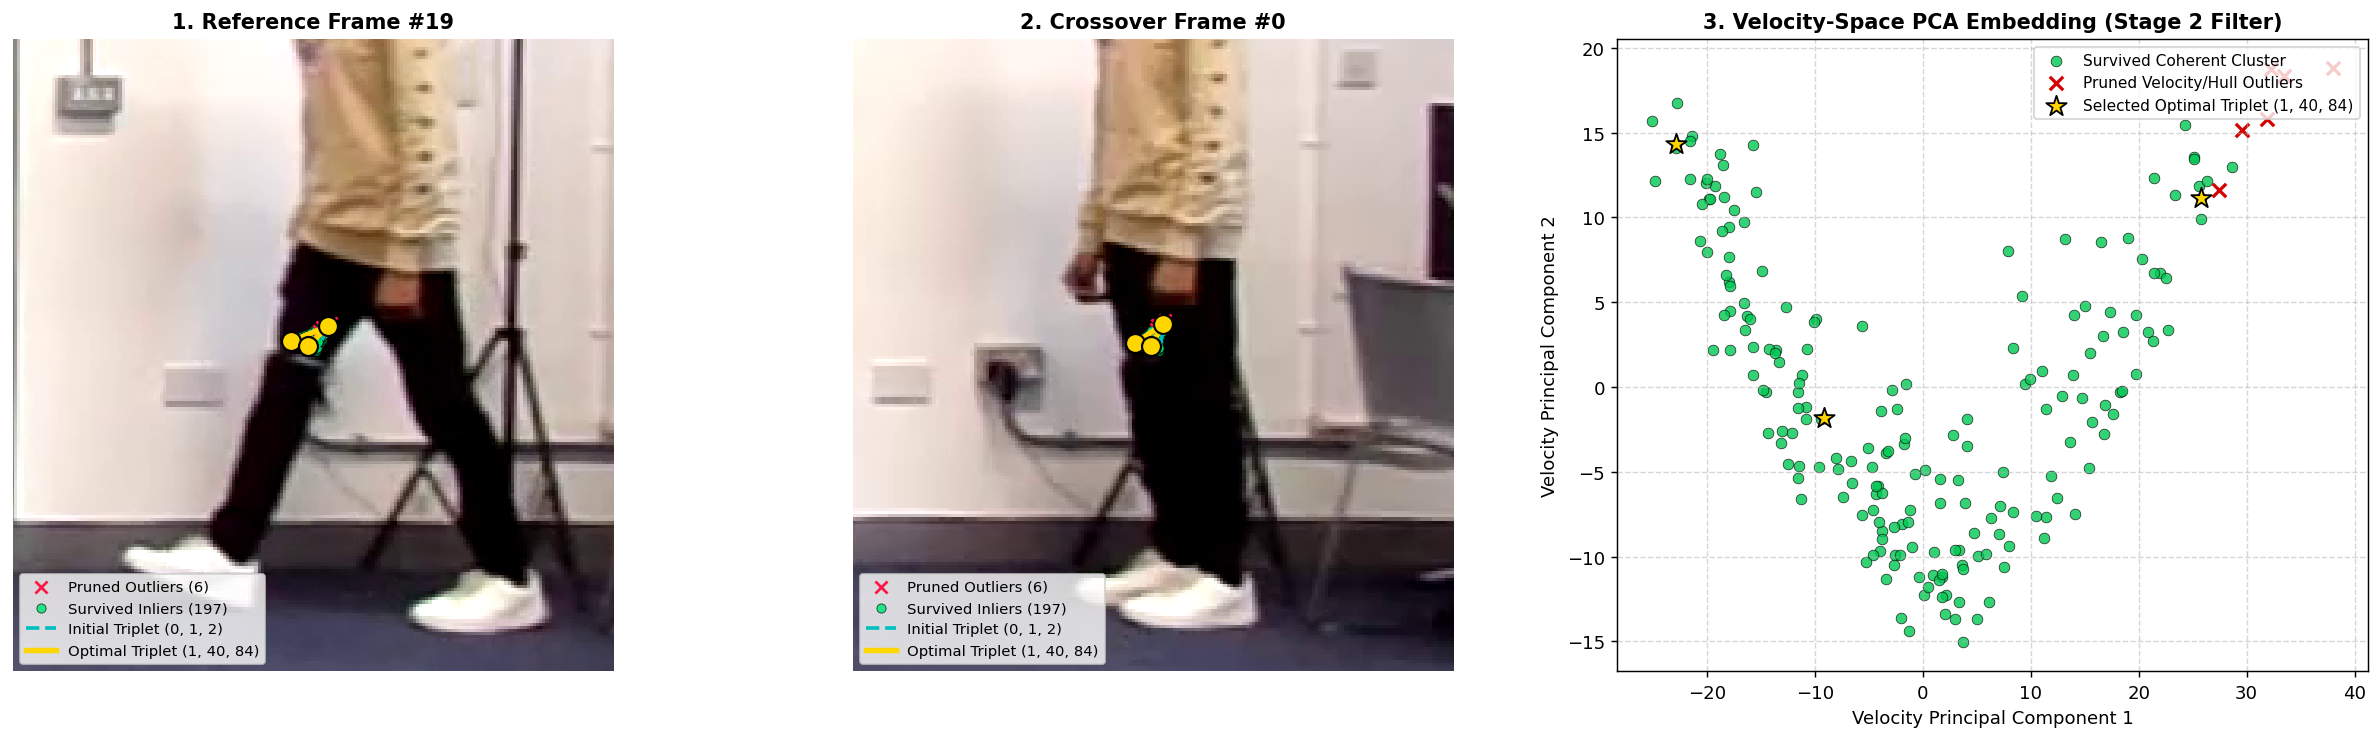

In [3]:
from src.data_io.dataset_scanner import DatasetScanner
from src.data_io.video_reader import video_provider

scanner = DatasetScanner(str(project_root / "data"))
v_info = next(v for v in scanner if v.name == video_name)

# Compute 2D PCA embedding of 3D velocity profiles across all 203 thigh points
vels = np.diff(t3d_smooth, axis=0).transpose(1, 0, 2).reshape(203, -1)
vels_pca = PCA(n_components=2).fit_transform(StandardScaler().fit_transform(vels))

fig, axes = plt.subplots(1, 3, figsize=(19, 5.8))

for ax_idx, (r_frame, title_str) in enumerate([(ref_idx_rel, f"1. Reference Frame #{ref_frame_idx}"), (max(0, ref_idx_rel - 20), f"2. Crossover Frame #{start_idx + max(0, ref_idx_rel - 20)}")]):
    abs_f = start_idx + r_frame
    f_bgr, _ = video_provider.get_frame(project_root / v_info.video_path, abs_f)
    f_rgb = cv2.cvtColor(f_bgr, cv2.COLOR_BGR2RGB)
    pts_px = t2d_smooth[r_frame] / scales

    ax = axes[ax_idx]
    ax.imshow(f_rgb)
    if len(rejected_indices) > 0:
        ax.scatter(pts_px[rejected_indices, 0], pts_px[rejected_indices, 1], c="#FF1744", marker="x", s=45, lw=1.5, label=f"Pruned Outliers ({len(rejected_indices)})", zorder=6)
    ax.scatter(pts_px[survived_indices, 0], pts_px[survived_indices, 1], c="#00E676", s=26, edgecolors="black", lw=0.4, alpha=0.85, label=f"Survived Inliers ({len(survived_indices)})", zorder=5)

    # Plot initial query triplet (0,1,2) vs Optimal Rigid Triplet
    orig_tri = np.vstack([pts_px[[0, 1, 2]], pts_px[0]])
    opt_tri = np.vstack([pts_px[list(best_triplet)], pts_px[best_triplet[0]]])
    ax.plot(orig_tri[:, 0], orig_tri[:, 1], "c--", lw=2.0, label="Initial Triplet (0, 1, 2)", zorder=8)
    ax.plot(opt_tri[:, 0], opt_tri[:, 1], color="#FFD600", lw=3.0, label=f"Optimal Triplet {best_triplet}", zorder=9)
    ax.scatter(opt_tri[:-1, 0], opt_tri[:-1, 1], c="#FFD600", s=110, edgecolors="black", lw=1.2, zorder=10)

    cx, cy = np.median(pts_px[survived_indices], axis=0)
    ax.set_xlim(cx - 95, cx + 95)
    ax.set_ylim(cy + 105, cy - 95)
    ax.set_title(title_str, fontsize=11.5, fontweight="bold")
    ax.legend(loc="lower left", fontsize=8.2)
    ax.axis("off")

# Panel 3: PCA Velocity Space
ax3 = axes[2]
ax3.scatter(vels_pca[survived_indices, 0], vels_pca[survived_indices, 1], c="#00C853", s=35, edgecolors="black", lw=0.4, alpha=0.8, label="Survived Coherent Cluster")
if len(rejected_indices) > 0:
    ax3.scatter(vels_pca[rejected_indices, 0], vels_pca[rejected_indices, 1], c="#D50000", marker="x", s=55, lw=1.8, label="Pruned Velocity/Hull Outliers")
ax3.scatter(vels_pca[list(best_triplet), 0], vels_pca[list(best_triplet), 1], c="#FFD600", s=140, marker="*", edgecolors="black", lw=1.0, zorder=10, label=f"Selected Optimal Triplet {best_triplet}")
ax3.set_title("3. Velocity-Space PCA Embedding (Stage 2 Filter)", fontsize=11.5, fontweight="bold")
ax3.set_xlabel("Velocity Principal Component 1")
ax3.set_ylabel("Velocity Principal Component 2")
ax3.legend(loc="upper right", fontsize=8.5)
ax3.grid(True, ls="--", alpha=0.5)

plt.tight_layout()
plt.show()

## 3. Temporal Rigidity & 3D Triangle Area Stability Comparison

Below we compare the temporal stability of the **Unpruned Initial Query Triplet `(0, 1, 2)`** against the **Optimal Pruned Rigid Triplet** across all $T = 143$ frames.

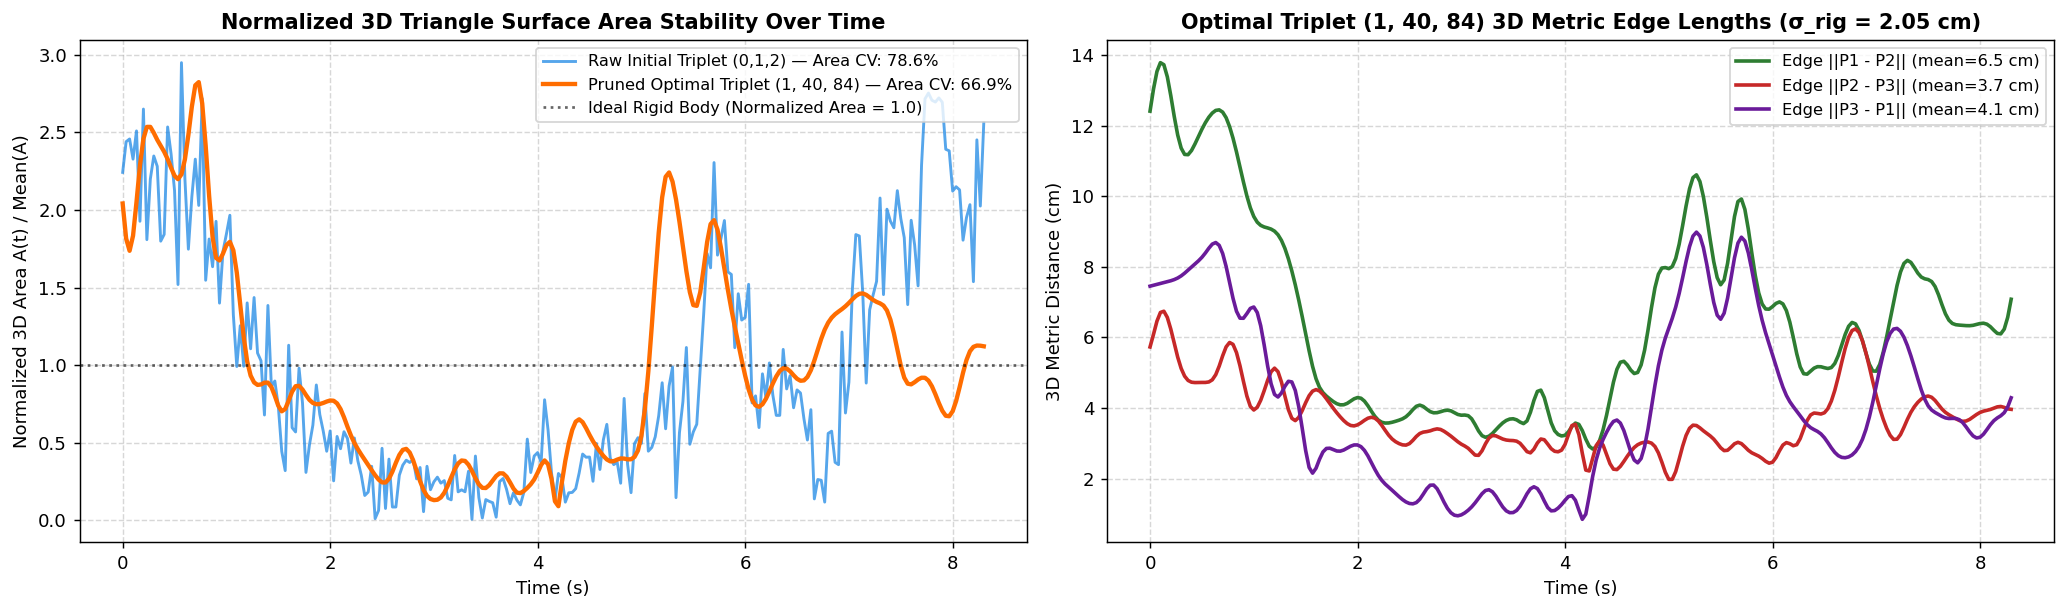

In [4]:
t_sec = np.arange(len(t3d_smooth)) / fps

# Compute 3D triangle areas over time
p_raw_3d = track3d_raw[:, [0, 1, 2], :]
area3d_raw = calc_area_3d(p_raw_3d[:, 0], p_raw_3d[:, 1], p_raw_3d[:, 2]) * 1e4  # cm²

p_opt_3d = t3d_smooth[:, list(best_triplet), :]
area3d_opt = calc_area_3d(p_opt_3d[:, 0], p_opt_3d[:, 1], p_opt_3d[:, 2]) * 1e4  # cm²

# Compute pairwise edge lengths for the optimal triplet (in cm)
d12_opt = np.linalg.norm(p_opt_3d[:, 0] - p_opt_3d[:, 1], axis=-1) * 100
d23_opt = np.linalg.norm(p_opt_3d[:, 1] - p_opt_3d[:, 2], axis=-1) * 100
d31_opt = np.linalg.norm(p_opt_3d[:, 2] - p_opt_3d[:, 0], axis=-1) * 100

cv_raw = np.std(area3d_raw) / (np.mean(area3d_raw) + 1e-9) * 100
cv_opt = np.std(area3d_opt) / (np.mean(area3d_opt) + 1e-9) * 100

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 4.8))
ax1.plot(t_sec, area3d_raw / np.mean(area3d_raw), color="#1E88E5", alpha=0.75, lw=1.6, label=f"Raw Initial Triplet (0,1,2) — Area CV: {cv_raw:.1f}%")
ax1.plot(t_sec, area3d_opt / np.mean(area3d_opt), color="#FF6D00", lw=2.4, label=f"Pruned Optimal Triplet {best_triplet} — Area CV: {cv_opt:.1f}%")
ax1.axhline(1.0, color="black", ls=":", alpha=0.6, label="Ideal Rigid Body (Normalized Area = 1.0)")
ax1.set_title("Normalized 3D Triangle Surface Area Stability Over Time", fontsize=11.5, fontweight="bold")
ax1.set_xlabel("Time (s)")
ax1.set_ylabel("Normalized 3D Area A(t) / Mean(A)")
ax1.legend(loc="upper right", fontsize=9)
ax1.grid(True, ls="--", alpha=0.5)

ax2.plot(t_sec, d12_opt, label=f"Edge ||P1 - P2|| (mean={np.mean(d12_opt):.1f} cm)", lw=2.0, color="#2E7D32")
ax2.plot(t_sec, d23_opt, label=f"Edge ||P2 - P3|| (mean={np.mean(d23_opt):.1f} cm)", lw=2.0, color="#C62828")
ax2.plot(t_sec, d31_opt, label=f"Edge ||P3 - P1|| (mean={np.mean(d31_opt):.1f} cm)", lw=2.0, color="#6A1B9A")
ax2.set_title(f"Optimal Triplet {best_triplet} 3D Metric Edge Lengths (σ_rig = {rig_opt.sigma_rigidity*100:.2f} cm)", fontsize=11.5, fontweight="bold")
ax2.set_xlabel("Time (s)")
ax2.set_ylabel("3D Metric Distance (cm)")
ax2.legend(loc="upper right", fontsize=9)
ax2.grid(True, ls="--", alpha=0.5)

plt.tight_layout()
plt.show()